# **Indian Union Budget 2026-2027 Analysis**




## 📖 1. Motive / Backstory
The **Union Budget of India** is the most highly anticipated economic event of the year. Delivered by the Hon'ble Finance Minister in the Parliament, this comprehensive speech doesn't just allocate funds—it sets the economic narrative, defines the government's priorities, and influences market sentiment for the entire fiscal year. 

However, a 30 to 40-page technical speech can be overwhelming to digest manually. While news channels provide summarized highlights, the raw, authentic tone and granular focus of the government often get lost in media interpretation. As data enthusiasts, we can leverage **Natural Language Processing (NLP)** to bypass the noise, directly analyze the authentic Parliamentary text, and let the data reveal the true focus of the budget.

---

## 🎯 2. Problem Statement
**Objective:** To systematically analyze the latest Union Budget Speech of India using Natural Language Processing (NLP) to extract underlying sentiments, dominant themes, and key sector priorities.

**Specific Goals of this Project:**
1. **Automated Extraction:** Fetch and parse the authentic budget speech document directly from the official India Budget portal.
2. **Text Processing (Cleaning):** Standardize the raw text by removing stop words, legal jargon, and punctuations to prepare a clean corpus.
3. **Thematic EDA:** Identify the most frequently emphasized words and sectors (e.g., Agriculture, Technology, Defense) to visualize the government's core focus areas using WordClouds and Frequency Plots.
4. **Sentiment & Tone Analysis:** Apply sentiment analysis to understand the emotional trajectory of the speech—identifying whether the overall tone is optimistic (growth-oriented), neutral (factual allocations), or cautious (focusing on inflation/deficits).

### **Library Importation**

In [1]:
!pip install python-dotenv groq google-generativeai google-genai

In [25]:
import numpy as np
import pandas as pd
import requests
import os
import seaborn as sns
import nltk
import string
import ollama
import matplotlib.pyplot as plt
from google import genai
from google.genai import types
from docx import Document
from wordcloud import WordCloud
from textblob import TextBlob
from nltk.util import ngrams
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from collections import Counter
from scipy import stats
from dotenv import load_dotenv
from groq import Groq

import warnings
warnings.filterwarnings("ignore")


In [3]:
import nltk
import ssl


try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

nltk.download('punkt')
nltk.download('punkt_tab') 
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [4]:
url = "https://www.indiabudget.gov.in/doc/budget_speech.docx"

file_name = "Budget_Speech_2026-27.docx"

print("Fetching Data of Authentic Indian Budget via official website........")

response = requests.get(url)

if response.status_code == 200:
    with open(file_name, "wb") as f:
        f.write(response.content)
        print(f'Data Successfully Downloaded as {file_name}')


else:

    print("Failed to Download the Data due to some unexpected error")



doc = Document(file_name)
li = []

for i in doc.paragraphs:
    text = i.text.strip()
    if text:
        li.append(text)

Fetching Data of Authentic Indian Budget via official website........
Data Successfully Downloaded as Budget_Speech_2026-27.docx


In [5]:
doc = Document(file_name)
li = []

for i in doc.paragraphs:
    text = i.text.strip()
    if text:
        li.append(text)
        
print(f"\n✅ Extraction Complete! The speech contains {len(li)} paragraphs.")

print("\n--- Initial Look at Data ---")
print(li[:2])


✅ Extraction Complete! The speech contains 439 paragraphs.

--- Initial Look at Data ---
['Budget 2026-2027', 'Speech of']


In [6]:
stop_words = set(stopwords.words("english"))


custom_stop_words = stop_words.union({'crore', 'lakh', 'rupees', 'lakhs', 'crores', 'government', 'year', 'also', 'budget', 'per', 'cent', 'rs', 'percent', "rate"})


def clean_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = ''.join([i for i in text if not i.isdigit()])
    

    y = word_tokenize(text)

    cleaned_text = [w for w in y if w not in custom_stop_words and len(w) > 2]

    return " ".join(cleaned_text)


clean_paras = [clean_text(q) for q in li]

full_cleaned_Speech = " ".join(clean_paras)


print("Data Cleaning Completed")

print("Cleaned preview:", clean_paras[10][:100],"....")

Data Cleaning Completed
Cleaned preview: today face external environment trade multilateralism imperilled access resources supply chains disr ....


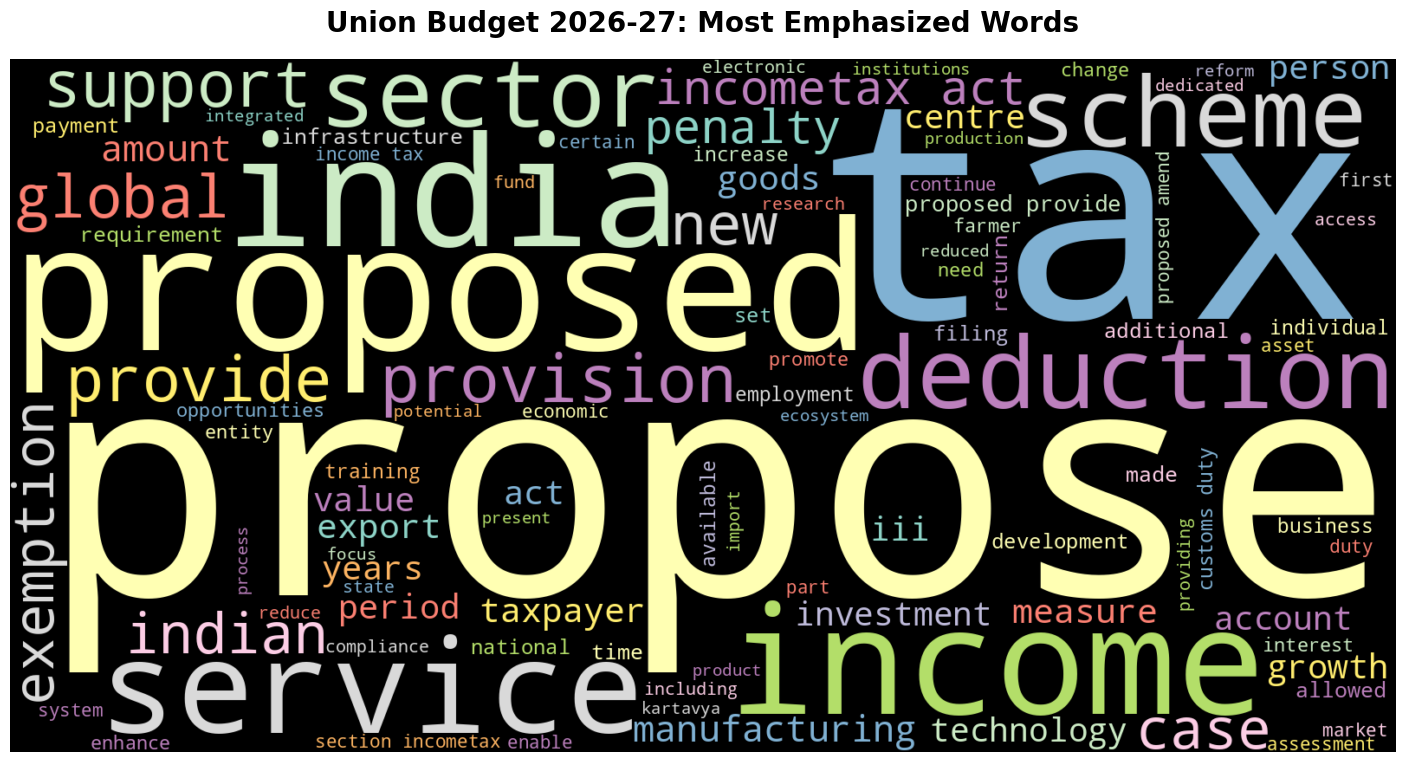

In [7]:
plt.figure(figsize=(18,9))
cloud = WordCloud(width=1600,height=800,background_color="black", colormap='Set3', max_words=101).generate(full_cleaned_Speech)
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Union Budget 2026-27: Most Emphasized Words", fontsize=20, fontweight='bold', pad=20)
plt.show()

In [8]:
ls = full_cleaned_Speech.split()
cnt = Counter(ls)
top10 = cnt.most_common(10)

df = pd.DataFrame(top10, columns=['Word', 'Frequency'])
df

,Word,Frequency
0,proposed,100
1,tax,98
2,propose,97
3,income,69
4,india,52
5,provide,48
6,act,47
7,section,39
8,services,34
9,deduction,34


In [9]:
bigrams = ngrams(ls,2)
bigrams_freq = Counter(bigrams)


top10_bigrams = bigrams_freq.most_common(10)
bigrams_data = {"Bigrams" : [f"{q[0][0]} {q[0][1]}" for q in top10_bigrams],
                "Count" : [q[1] for q in top10_bigrams]}


df_bigrams = pd.DataFrame(bigrams_data)
df_bigrams

,Bigrams,Count
0,incometax act,22
1,proposed provide,16
2,customs duty,13
3,income tax,11
4,section incometax,11
5,proposed amend,11
6,tax regime,9
7,provide exemption,9
8,viksit bharat,8
9,propose provide,8


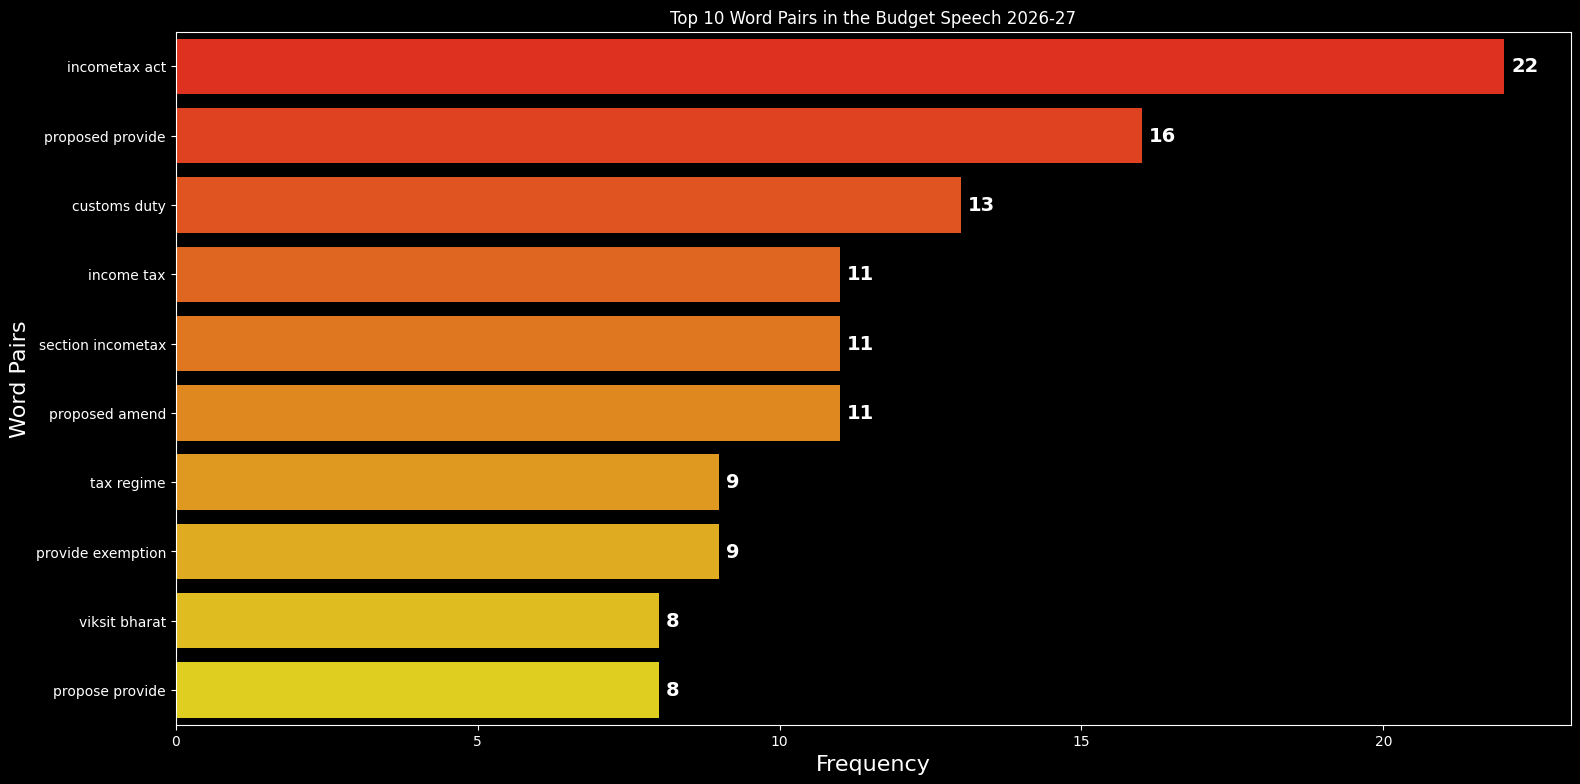

In [35]:
plt.style.use("dark_background") 

plt.figure(figsize=(18,9))
bar = sns.barplot(x="Count", y="Bigrams", data=df_bigrams, palette="autumn")

for i in bar.containers:

    bar.bar_label(i, padding=5, color='white', fontsize=14, fontweight='bold')

plt.title('Top 10 Word Pairs in the Budget Speech 2026-27')
plt.xlabel("Frequency", fontsize=16)
plt.ylabel("Word Pairs", fontsize=16)
plt.show()

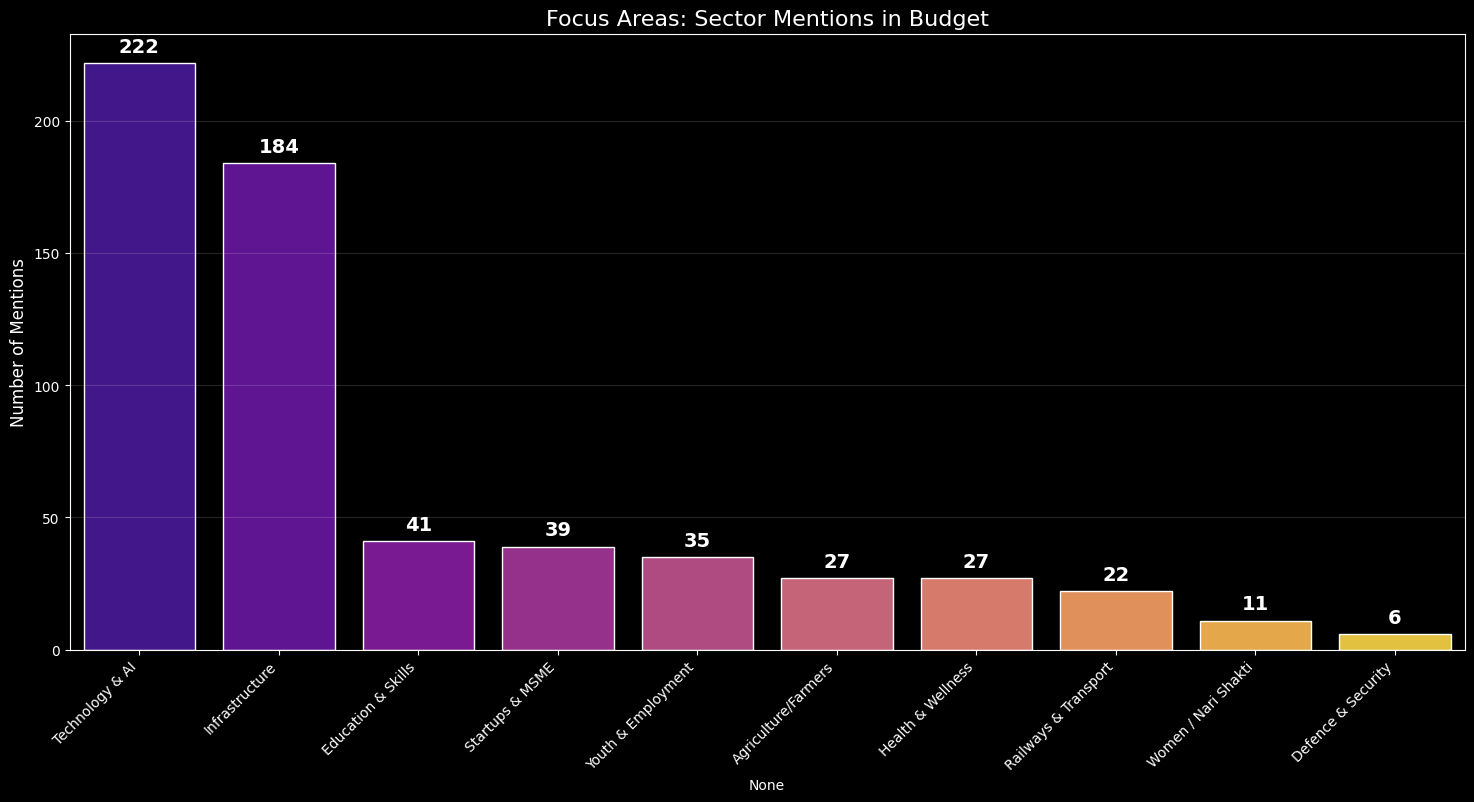

In [11]:
sec = {
    'Agriculture/Farmers': ['agriculture', 'farmer', 'farmers', 'kisan', 'crop', 'crops', 'rural', 'irrigation'],
    'Education & Skills': ['education', 'school', 'schools', 'college', 'university', 'students', 'learning', 'skill', 'skills'],
    'Health & Wellness': ['health', 'hospital', 'hospitals', 'medical', 'disease', 'vaccine', 'nutrition', 'ayushman'],
    'Railways & Transport': ['rail', 'railway', 'railways', 'train', 'trains', 'vande bharat', 'station', 'metro'],
    'Technology & AI': ['technology', 'digital', 'tech', 'ai', 'innovation', 'artificial intelligence', 'research'],
    'Defence & Security': ['defence', 'military', 'army', 'navy', 'airforce', 'armed forces', 'border'],
    'Women / Nari Shakti': ['women', 'woman', 'girl', 'girls', 'nari', 'shakti', 'mahila', 'matru'],
    'Youth & Employment': ['youth', 'young', 'employment', 'jobs', 'job', 'rozgar', 'career'],
    'Startups & MSME': ['startup', 'startups', 'msme', 'msmes', 'entrepreneur', 'entrepreneurship', 'business', 'businesses'],
    'Infrastructure': ['infrastructure', 'infra', 'roads', 'highway', 'highways', 'bridge', 'bridges', 'port', 'ports', 'aviation']
}

dict = {}

for sector_name, word_list in sec.items():
    total = 0
    for word in word_list:
        total += full_cleaned_Speech.count(word)
    dict[sector_name] = total

df_sec = pd.Series(dict).sort_values(ascending=False)

plt.figure(figsize=(18,8))
ax = sns.barplot(x=df_sec.index, y=df_sec.values, palette='plasma', edgecolor="white")

for container in ax.containers:
    ax.bar_label(container, padding=5, color='white', fontsize=14, fontweight='bold')

plt.title("Focus Areas: Sector Mentions in Budget", fontsize=16)
plt.ylabel("Number of Mentions", fontsize=12)
plt.xticks(rotation=45, ha='right') 
plt.grid(axis='y', alpha=0.15)
plt.style.use('dark_background')
plt.show()

In [12]:
lt = []

for i in clean_paras:
    if len(i) > 10:
        blob = TextBlob(i)

        lt.append(blob.sentiment.polarity)


df_sentiments = pd.DataFrame(lt, columns=['Polarity'])

avg_sentiment = df_sentiments["Polarity"].mean()




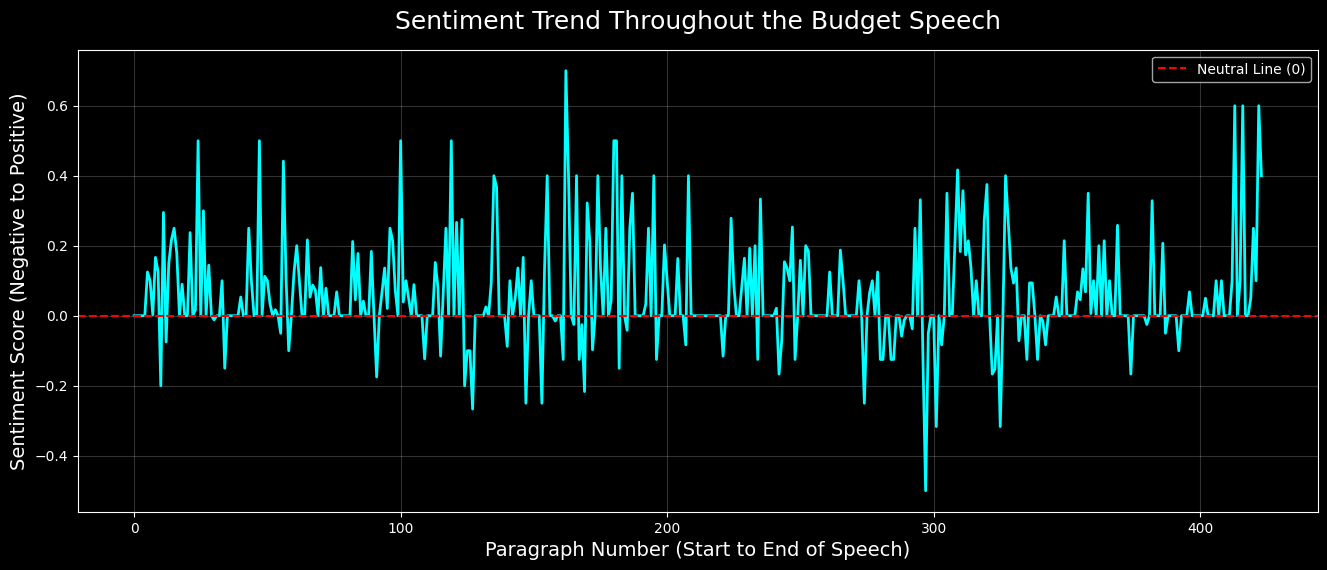

Sentiment Analysis Results
---------------------------------------------
Overall Tone: POSITIVE (Optimistic & Growth-oriented) | Score: 0.057


In [13]:
plt.figure(figsize=(16, 6))
plt.plot(df_sentiments['Polarity'], color='cyan', linewidth=2)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Neutral Line (0)')
plt.title("Sentiment Trend Throughout the Budget Speech", fontsize=18, pad=15)
plt.xlabel("Paragraph Number (Start to End of Speech)", fontsize=14)
plt.ylabel("Sentiment Score (Negative to Positive)", fontsize=14)
plt.legend()
plt.grid(alpha=0.2)
plt.style.use('dark_background')
plt.show()


print('Sentiment Analysis Results')
print("-"*45)
if avg_sentiment > 0.05:
        print(f"Overall Tone: POSITIVE (Optimistic & Growth-oriented) | Score: {avg_sentiment:.3f}")
elif avg_sentiment < -0.05:
    print(f"Overall Tone: CAUTIOUS / NEGATIVE | Score: {avg_sentiment:.3f}")
else:
    print(f"Overall Tone: NEUTRAL (Factual/Balanced) | Score: {avg_sentiment:.3f}")

In [14]:
desc_stats = df_sentiments[['Polarity']].describe().T.round(3)

desc_stats.columns = ['Total Paragraphs', 'Average (Mean)', 'Std Dev', 'Minimum', '25%', 'Median', '75%', 'Maximum']
desc_stats.index = ['Sentiment Tone']

desc_stats

,Total Paragraphs,Average (Mean),Std Dev,Minimum,25%,Median,75%,Maximum
Sentiment Tone,424.0,0.057,0.148,-0.5,0.0,0.0,0.1,0.7


In [15]:
mp = len(df_sentiments)//2

hf1 = df_sentiments['Polarity'][:mp]
hf2 = df_sentiments['Polarity'][mp:]

print(f"First Half Average Sentiment: {hf1.mean():.3f}")
print(f"Second Half Average Sentiment: {hf2.mean():.3f}")


t_stat, pval = stats.ttest_ind(hf1, hf2)

print(f'''T-Test hypothesis 
Test Statistic Value = {t_stat:.4f}
P Value = {pval:.4f}''')


if pval < 0.05:

    print("\nConclusion: P-value is lower 0.05 threshold.")
    print("This refers to that we have a significant difference between tone of first half and second half")
else:
    print("\nConclusion: P-value is higher than 0.05 threshold.")
    print("This refers to that we don't have a significant difference between tone of first half and second half")



First Half Average Sentiment: 0.070
Second Half Average Sentiment: 0.045
T-Test hypothesis 
Test Statistic Value = 1.7271
P Value = 0.0849

Conclusion: P-value is higher than 0.05 threshold.
This refers to that we don't have a significant difference between tone of first half and second half


In [16]:
from IPython.display import display, Markdown

def model_eval(model, text_data):

    print(f"{model.upper()} is analyzing the budget......")

    # Aapka exact same prompt, maine isme 1 word bhi change nahi kiya hai
    prompt =f"""You are a highly skilled Economic Analyst and Data Scientist analyzing the Indian Union Budget Speech. 

Based strictly on the provided budget speech text, I need a comprehensive, structured, and highly detailed analysis broken down into the following three specific sections:

### 1. Sector-Wise Allocations & Focus
Provide a detailed breakdown of what specific announcements, funds, or policies were made for the following 10 sectors. (If a sector was not significantly mentioned, state "Limited mentions"):
- Agriculture & Farmers
- Education & Skills
- Health & Wellness
- Railways & Transport
- Technology & AI
- Defence & Security
- Women / Nari Shakti
- Youth & Employment
- Startups & MSME
- Infrastructure

### 2. The 'Rupee Comes From' Analysis (Revenue)
Explain the government's revenue model. If the government earns 100 Rupees, break down exactly where this money is coming from (e.g., Corporate Tax, Income Tax, GST, Borrowings, Non-tax revenue, etc.). Provide the exact percentages or paise breakdown if mentioned in the text.

### 3. The 'Rupee Goes To' Analysis (Expenditure)
Explain the government's expenditure model. If the government spends 100 Rupees, break down exactly where it is going (e.g., Interest Payments, Defence, Subsidies, State shares, Pensions, Central Sector Schemes, etc.). Provide the exact percentages or paise breakdown if mentioned in the text.

Format your response clearly using Markdown, bold text for key numbers, and bullet points. Do not hallucinate; use only the data present in the text provided below.

---
BUDGET SPEECH TEXT:
{text_data}
"""
    
    try:
        response = ollama.chat(model=model, messages=[{'role' : "user", "content" :prompt}])
        print(f'\n {model.upper()} Budget Analysis')
        print("=" * 60)
        
        # YAHAN CHANGE KIYA HAI: print() hata diya, aur display(Markdown()) laga diya
        # Issey Output scrollable nahi aayega, balki professional formatted aayega
        display(Markdown(response['message']['content']))
        
        print("=" * 60 + "\n")

    except Exception as e:
        print("ERROR with Ollama Models therefore Kindly Check Again..............")

In [17]:
budget_doc = " ".join(li)
model_eval('phi3', budget_doc )

PHI3 is analyzing the budget......

 PHI3 Budget Analysis


The document discusses various proposed amendments related to indirect taxation laws in India with an aim to simplify them and ensure uniformity across different states by bringing more items under one schedule of duty, rationalizing the existing provisions for setting up treasury centres (TCS), disability pensions for armed forces members etc. 
It is also proposing a reduction or elimination of customs duties on various goods to reduce input costs and promote domestic manufacturing/exports along with changes in export promotion measures including exemption of Central Excise duty, revamped National Calamity Contingent Duty rate among others for better alignment. 
Additionally, it talks about the rationalization or removal of various deductions related to interest on borrowings and capital gains from mutual funds etc., proposes clarifications regarding certain legal issues like time-limit for assessments post Dispute Resolution Panel proceedings/Transfer Pricing Officer order, Document Identification Number (DIN) & issuance of notice for reassessment by Jurisdictional Assessing Officer and amendments in the definitions related to 'commodity derivative'/'authorised person'. 
It also proposes changes concerning tonnage tax scheme provisions. Finally, it touches upon some proposed modifications relating to Income Tax Act, like treasury centre regulations etc.

In [18]:
budget_doc = " ".join(li)
model_eval('llama3.1', budget_doc )

LLAMA3.1 is analyzing the budget......

 LLAMA3.1 Budget Analysis


The Budget Proposals for Direct Taxes include several key points related to search assessment, block period, and extension of income tax slabs. Some of the notable points are:

*   The block period for a person against whom no search or requisition was initiated will be limited to 1 year if the undisclosed income pertains only to one tax year.
*   The time limit to complete search assessment is being extended from 12 months to 18 months in the case of specified persons.
*   The facility for updating tax returns has been extended even after reassessment proceedings have been initiated, with an additional 10% tax rate applicable.
*   Penalty for non-furnishing of statement or furnishing inaccurate information in a statement on transaction of crypto-assets is proposed to be introduced.

The Budget Proposals for Indirect Taxes include changes related to customs duty rates, exemptions, and export promotion measures. Some of the notable points are:

*   Customs duty rates are being reduced on certain items to reduce input costs, boost domestic manufacturing, and promote export competitiveness.
*   Exemptions are being lapsed or modified with effect from 02.02.2026 or 01.04.2026, resulting in no change in the effective rate of duty on the goods.
*   The Seventh Schedule to the Finance Act, 2001 is being amended to revise the National Calamity Contingent Duty (NCCD) Rate with effect from 01.05.2026, maintaining the effective duty rate at 25%.

Overall, these budget proposals aim to provide relief and incentives for various sectors while promoting economic growth and development.

Additionally, there are other minor modifications in the Income-tax Act, 2025, including providing definitions of "commodity derivative" and "authorised person", correcting referencing errors, and amending sections related to registered non-profit organisations.

In [19]:
budget_doc = " ".join(li)
model_eval('qwen2', budget_doc )

QWEN2 is analyzing the budget......

 QWEN2 Budget Analysis


The proposed amendments in the Direct Tax regime include:

1) Increasing the tax threshold to Rs.10 lakh from Rs.7.5 lakh annually for individuals not availing deductions.

2) Introducing a 30% tax slab starting at Rs.40 lakh annual income, replacing existing tax slabs of 20%, 30% and 37%.

3) A new 60% surcharge is proposed on incomes exceeding Rs.2 crores.

4) Tax exemption limit for Senior Citizens raised to Rs.10.5 lakh from Rs.8 lakh annually.

5) Dividend income tax rate revised to 20%, and the long-term capital gains tax rate reduced to 15%.

6) Reduction in corporate tax rates, with no minimum alternate tax applicable after a transition period.

7) Introduction of new tax regime with lower tax rates for companies opting out of the old system.

8) Relaxations for new business start-ups including tax exemptions and incentives.

9) Changes to indirect taxes like customs duty rate adjustments, review of export-oriented exemptions, and export promotion measures.

10) Amendments to various provisions in the Income Tax Act such as rationalization of tax collection at source (TCS), share buyback rules, dividend income taxation, etc.

The focus is on simplification, promoting new businesses/start-ups, incentivizing manufacturing/exports, attracting foreign investment, and reducing compliance burden for taxpayers.

In [20]:
import os
from dotenv import load_dotenv

# .env file ko read karna
load_dotenv()

GROQ_KEY = os.getenv("GROQ_API_KEY")
GEMINI_KEY = os.getenv("GEMINI_API_KEY")


if GROQ_KEY:
    print(f" GROQ Key Loaded Successfully! (Starts with: {GROQ_KEY[:4]}...)")
else:
    print(" GROQ Key Not Found!")

# Check Gemini Key
if GEMINI_KEY:
    print(f"GEMINI Key Loaded Successfully! (Starts with: {GEMINI_KEY[:4]}...)")
else:
    print("GEMINI Key Not Found!")

 GROQ Key Loaded Successfully! (Starts with: gsk_...)
GEMINI Key Loaded Successfully! (Starts with: AQ.A...)


In [32]:
def gemini_model_eval(text_data):
    print("⏳ GEMINI is analyzing the budget......\n")

    prompt = f"""You are a highly skilled Economic Analyst and Data Scientist analyzing the Indian Union Budget Speech. 
Based strictly on the provided budget speech text, I need a comprehensive, structured, and highly detailed analysis broken down into the following three specific sections. 

CRITICAL RULE: You MUST output all three sections as Markdown Tables. 
CRITICAL INSTRUCTION: Keep the analysis EXTREMELY CONCISE. Provide a MAXIMUM of 3 very short bullet points per sector. Do not repeat any points.

### 1. Sector-Wise Allocations & Focus
Create a Markdown Table with two columns: 'Sector' and 'Key Announcements/Allocations'. 
Analyze these 10 sectors: Agriculture & Farmers, Education & Skills, Health & Wellness, Railways & Transport, Technology & AI, Defence & Security, Women / Nari Shakti, Youth & Employment, Startups & MSME, Infrastructure. (If not mentioned, write 'Limited mentions').

### 2. The 'Rupee Comes From' Analysis (Revenue)
Create a Markdown Table with two columns: 'Revenue Source' and 'Details/Percentage'. (If exact numbers aren't there, summarize major tax sources).

### 3. The 'Rupee Goes To' Analysis (Expenditure)
Create a Markdown Table with two columns: 'Expenditure Area' and 'Details/Percentage'. (If exact numbers aren't there, summarize major spending areas).

Do not hallucinate; use only the data present in the text provided below.
---
BUDGET SPEECH TEXT:
{text_data}
"""
    
    try:
        client = genai.Client(api_key=os.getenv("GEMINI_API_KEY"))
        
        response = client.models.generate_content(
            model='gemini-3.5-flash',
            contents=prompt,
            config=types.GenerateContentConfig(
                temperature=0.2,
            )
        )
            
        print('🌟 GEMINI Budget Analysis 🌟')
        print("=" * 60)
        display(Markdown(response.text))
        print("=" * 60 + "\n")
        
    except Exception as e:
        print(f"❌ ERROR with GEMINI API: {e}")

In [33]:
gemini_model_eval(budget_doc)

⏳ GEMINI is analyzing the budget......

🌟 GEMINI Budget Analysis 🌟


### 1. Sector-Wise Allocations & Focus

| Sector | Key Announcements/Allocations |
| :--- | :--- |
| **Agriculture & Farmers** | <ul><li>**Bharat-VISTAAR**: Launching a multilingual AI tool integrating AgriStack and ICAR advisory.</li><li>**Horticulture & Cash Crops**: Focused schemes for coconut (replacing old trees), cashew, cocoa, and sandalwood.</li><li>**Allied Sectors**: Credit-linked subsidies for animal husbandry and integrated development of 500 fisheries reservoirs.</li></ul> |
| **Education & Skills** | <ul><li>**University Townships**: Supporting states to build 5 planned academic townships near industrial corridors.</li><li>**Infrastructure**: Establishing 1 girls' hostel in every district to support STEM higher education.</li><li>**Specialized Skilling**: Launching Samarth 2.0 for textiles and AVGC Content Creator Labs in 15,000 schools.</li></ul> |
| **Health & Wellness** | <ul><li>**Biopharma SHAKTI**: ₹10,000 crore outlay over 5 years to boost domestic biologics and biosimilars.</li><li>**Capacity Building**: Adding 100,000 Allied Health Professionals and training 1.5 lakh caregivers.</li><li>**Tax Relief**: Customs duty exemptions on 17 cancer drugs and 7 rare disease drugs.</li></ul> |
| **Railways & Transport** | <ul><li>**High-Speed Rail**: Developing 7 new high-speed rail corridors (e.g., Mumbai-Pune, Delhi-Varanasi).</li><li>**Waterways & Freight**: Operationalizing 20 new National Waterways and establishing Dankuni-Surat Freight Corridor.</li><li>**Seaplanes**: Launching a Seaplane VGF Scheme and incentives to indigenize manufacturing.</li></ul> |
| **Technology & AI** | <ul><li>**Semiconductors**: Launching ISM 2.0 to produce equipment, materials, and full-stack Indian IP.</li><li>**Electronics**: Increasing Electronics Components Manufacturing Scheme outlay to ₹40,000 crore.</li><li>**AI Integration**: Deploying AI in agriculture (Bharat-VISTAAR) and upgrading customs risk systems.</li></ul> |
| **Defence & Security** | <ul><li>**Customs Exemptions**: BCD exempted on raw materials for aircraft parts imported for Defence MRO units.</li><li>**Disability Pension**: Specific tax exemptions introduced for disability pensions of Armed Forces and paramilitary personnel.</li><li>*Limited mentions*</li></ul> |
| **Women / Nari Shakti** | <ul><li>**SHE-Marts**: Setting up community-owned retail outlets for rural women-led enterprises.</li><li>**STEM Support**: Building 1 girls' hostel in every district to facilitate higher education.</li><li>**Lakhpati Didi**: Scaling up the program to transition women from credit-led livelihoods to enterprise owners.</li></ul> |
| **Youth & Employment** | <ul><li>**Standing Committee**: Setting up a high-powered 'Education to Employment and Enterprise' Committee.</li><li>**Tourism & Creative Jobs**: Upskilling 10,000 guides and targeting 2 million AVGC professionals by 2030.</li><li>**Waterways Training**: Setting up Regional Centres of Excellence to train youth along new waterways.</li></ul> |
| **Startups & MSME** | <ul><li>**SME Growth Fund**: Launching a ₹10,000 crore fund, plus ₹2,000 crore top-up for Self-Reliant India Fund.</li><li>**TReDS Integration**: Mandating TReDS for CPSE purchases and linking it with GeM for cheaper financing.</li><li>**Corporate Mitras**: Creating a cadre of accredited para-professionals in Tier-II/III towns for compliance.</li></ul> |
| **Infrastructure** | <ul><li>**Capital Expenditure**: Increasing public capex allocation to ₹12.2 lakh crore for FY 2026-27.</li><li>**Risk Mitigation**: Setting up an Infrastructure Risk Guarantee Fund to provide partial credit guarantees.</li><li>**CCUS**: Allocating ₹20,000 crore over 5 years for Carbon Capture Utilization and Storage.</li></ul> |

---

### 2. The 'Rupee Comes From' Analysis (Revenue)

| Revenue Source | Details/Percentage |
| :--- | :--- |
| **Net Tax Receipts (BE 2026-27)** | Estimated at **₹28.7 lakh crore** (out of total non-debt receipts of ₹36.5 lakh crore). |
| **Market Borrowings (BE 2026-27)** | **₹11.7 lakh crore** net market borrowings (Gross market borrowings estimated at **₹17.2 lakh crore**). |
| **Small Savings & Other Sources** | Utilized to finance the remaining fiscal deficit (estimated at 4.3% of GDP). |
| **Securities Transaction Tax (STT)** | Increased to **0.05%** on Futures and **0.15%** on Options to generate additional revenue. |
| **Promoter Buyback Tax** | Effective tax rate of **22%** for corporate promoters and **30%** for non-corporate promoters. |
| **Customs & Excise Duties** | Streamlined tariffs, including a 2% TCS on scrap/minerals and excise duty on biogas-blended CNG. |

---

### 3. The 'Rupee Goes To' Analysis (Expenditure)

| Expenditure Area | Details/Percentage |
| :--- | :--- |
| **Total Estimated Expenditure (BE 2026-27)** | Estimated at **₹53.5 lakh crore** (compared to ₹49.6 lakh crore in RE 2025-26). |
| **Public Capital Expenditure (BE 2026-27)** | Allocated **₹12.2 lakh crore** to maintain infrastructure momentum. |
| **Finance Commission Grants to States** | **₹1.4 lakh crore** provided for FY 2026-27 (vertical devolution share retained at **41%**). |
| **Strategic Industrial Schemes** | Includes **₹40,000 crore** for Electronics, **₹10,000 crore** for Biopharma, and **₹10,000 crore** for Container Manufacturing. |
| **MSME & Enterprise Support** | **₹10,000 crore** for the SME Growth Fund and **₹2,000 crore** for the Self-Reliant India Fund. |
| **Climate & Urban Infrastructure** | **₹20,000 crore** for CCUS over 5 years and **₹5,000 crore** per City Economic Region (CER). |